# Multilayer dispersion: comparison with TetraX

This example compares the dispersion relation of magnetic multilayers calculated by `MultiLayerNumeric` with finite-element micromagnetic calculations by [TetraX](https://tetrax.software/) (dynamic-matrix approach, Körber *et al.*).  `MultiLayerNumeric` generalizes `DoubleLayerNumeric` to an arbitrary number of magnetic layers, coupled by the dipolar interaction (all pairs of layers) and by the bilinear and biquadratic interlayer exchange (neighboring layers).  Two cases are shown:

1. a CoFeB/Py/CoFeB trilayer with different layer thicknesses, spacers and antiferromagnetic couplings, an in-plane uniaxial anisotropy in the bottom layer and a perpendicular anisotropy in the top layer, in an oblique field (partially out of the film plane, at a general in-plane angle to the wavevector), i.e. three tilted, non-collinear magnetizations,
2. a single 40 nm thick Py film modelled by 20 sublayers coupled by the interlayer exchange ``Jbl = 2*Aex/d_sub``, which reproduces the surface (Damon-Eshbach) mode and the perpendicular standing spin waves.

To run the TetraX part, TetraX (version 2) has to be installed in the Python environment, e.g. by ``pip install git+https://codebase.helmholtz.cloud/micromagnetic-modeling/tetrax.git``.  TetraX 2.0.0 is not compatible with SciPy 1.18 or newer out of the box, so the import cell adds a missing attribute as a workaround (see [SAF dispersion vs TetraX](SAF_dispersion_vs_TetraX.ipynb)).  TetraX writes its results to disk, here to a temporary folder in the working directory, which is deleted at the end of each calculation.

> **Conventions.**  TetraX describes layers along the $y$ axis (the film normal) with the wavevector along $z$, whereas `MultiLayerNumeric` has the normal along $z$ and measures the in-plane angles from the in-plane projection of the field (see the class documentation); both use the wave convention $e^{i(kx - \omega t)}$, so the frequencies are compared at the same wavevector.  The layers are numbered from the bottom (substrate side) in both codes.

In [1]:
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.linalg import LinearOperator
import SpinWaveToolkit as SWT
import tetrax as tx

print("SpinWaveToolkit", SWT.__version__, " TetraX", tx.__version__)

# TetraX 2.0.0 does not call `LinearOperator.__init__` in its spin-wave
# tensors, which SciPy >= 1.18 requires (it sets the array namespace
# `_xp` there): provide the default namespace as a class-level fallback
_op = LinearOperator((1, 1), matvec=lambda x: x)
if hasattr(_op, "_xp"):
    LinearOperator._xp = _op._xp

SpinWaveToolkit 1.3.0  TetraX 2.0.0


## Helper functions for TetraX

The frames of the two codes are mapped as $x_\mathrm{SWT} \to z_\mathrm{TetraX}$ (wavevector), $y_\mathrm{SWT} \to x_\mathrm{TetraX}$ and $z_\mathrm{SWT} \to y_\mathrm{TetraX}$ (normal).  The multilayer is a line trace along the normal (`tx.geometries.layer.multilayer`), the material parameters are assigned per node, and the interlayer exchange constants `J1` (same sign convention as `Jbl`, energy $-J\,\mathbf{m}_i\cdot\mathbf{m}_{i+1}$ per area) per spacer.  In TetraX 2.0.0, a list of `J1` constants (one per spacer) is not stored by the parameter setter (it returns None), so the setter is patched to keep the list.  TetraX supports one uniaxial anisotropy per node, which is either the in-plane (`Ku`) or the perpendicular (`Ks`) anisotropy of the layer here.  The relaxation starts from the equilibrium found by SpinWaveToolkit.

In [2]:
def to_tetrax(v):
    """Vector from the frame of SpinWaveToolkit (x || k, z || normal) to
    the frame of TetraX (z || k, y || normal)."""
    return np.array([v[1], v[2], v[0]])


def from_tetrax(v):
    """Vector from the frame of TetraX back to the frame of SWT."""
    return np.array([v[2], v[0], v[1]])


def unit_vector(theta, phi, phi_B):
    """Unit vector in the SWT frame x || k from the polar angle `theta`
    and the in-plane angle `phi` measured from the field (as the angles
    of the SWT equilibrium are), i.e. rotated by the angle phi_B of the
    field from the wavevector."""
    return np.array([np.sin(theta)*np.cos(phi + phi_B),
                     np.sin(theta)*np.sin(phi + phi_B),
                     np.cos(theta)])


def tetrax_multilayer(ml, angles, num_modes, cell_size=0.25):
    """Relax the multilayer described by the `MultiLayerNumeric` object
    `ml` in TetraX from the magnetization `angles` and calculate
    `num_modes` modes for the wavevectors ``ml.kxi >= 0`` (TetraX
    returns both signs).  Returns the layer averages of the relaxed
    magnetization (SWT frame), the wavevectors and the frequencies (Hz)."""
    L, phi_B = ml.nlayers, ml.phi
    workdir = os.path.abspath("tetrax_tmp")
    os.makedirs(workdir, exist_ok=True)
    cwd = os.getcwd()
    os.chdir(workdir)
    try:
        mesh = tx.geometries.layer.multilayer(list(ml.d*1e9), list(ml.s*1e9),
                                              cell_size)
        sample = tx.Sample(mesh, name="multilayer")
        # index of the layer of each node (the stack is centered at y = 0)
        bottoms = np.concatenate([[0.0], np.cumsum(ml.d[:-1] + ml.s)])*1e9
        bottoms -= (bottoms[-1] + ml.d[-1]*1e9)/2
        layer = np.searchsorted(bottoms, np.asarray(sample.xyz)[:, 1] + 1e-6) - 1

        sample.material["Msat"] = ml.Ms[layer]
        sample.material["Aex"] = ml.Aex[layer]
        sample.material["gamma"] = ml.gamma[layer]
        sample.material["alpha"] = ml.alpha
        if L > 1:
            # (TetraX 2.0.0: keep the list of J1 constants in the setter)
            param = sample.material._param_dict["J1"]
            setter = param._setter_function
            param._setter_function = (
                lambda name, val, mesh, glob: setter(name, val, mesh, glob)
                or list(val))
            sample.material["J1"] = [float(j) for j in ml.Jbl]
        # one uniaxial anisotropy per layer: in-plane (Ku) or perpendicular (Ks)
        assert np.all((ml.Ku == 0) | (ml.Ks == 0))
        axes = np.array([to_tetrax(unit_vector(np.pi/2, p, phi_B)) if ku != 0
                         else np.array([0.0, 1.0, 0.0])
                         for ku, p in zip(ml.Ku, ml.phiAnis)])
        sample.material["Ku1"] = (ml.Ku + ml.Ks)[layer]
        sample.material["e_u"] = axes[layer]
        sample.Bext = ml.Bext*to_tetrax(unit_vector(ml.theta, 0.0, phi_B))
        ms = np.array([to_tetrax(unit_vector(t, p, phi_B)) for t, p in angles.T])
        sample.mag = ms[layer]

        # (TetraX keeps the initial magnetization if the minimization does
        # not converge, which happens occasionally: repeat it until it does)
        for _ in range(5):
            relaxed = tx.experiments.relax(sample, verbose=False, save=False,
                                           set_initial_on_failure=False)
            if relaxed.was_success:
                break
        else:
            print("Warning: the TetraX relaxation did not converge.")
        mag = np.asarray(sample.mag)
        m_avg = np.array([from_tetrax(mag[layer == l].mean(axis=0))
                          for l in range(L)])
        eigen = tx.experiments.eigenmodes(sample, k=ml.kxi[ml.kxi >= 0],
                                          num_modes=num_modes,
                                          save_mode_profiles=False,
                                          verbose=False, num_cpus=1)
        k_tx = np.asarray(eigen.k)  # (rad/m) both signs of the wavevectors
        f_tx = np.asarray(eigen.frequencies()).T  # (num_modes, len(k_tx)) Hz
    finally:
        os.chdir(cwd)
        shutil.rmtree(workdir)  # also after an error
    return m_avg, k_tx, f_tx

## 1. Trilayer with non-collinear magnetizations in an oblique field

CoFeB(4 nm)/Ru(0.7 nm)/Py(6 nm)/Ru(1 nm)/CoFeB(3 nm) with antiferromagnetic couplings of different strengths, an in-plane uniaxial anisotropy in the bottom layer (easy axis along the in-plane field component) and a perpendicular anisotropy in the top layer.  The field of 80 mT is applied at 60° from the film normal and at 60° in-plane from the wavevector.

In [3]:
CFB = SWT.Material(Ms=1.2e6, Aex=15e-12, alpha=0.01, gamma=1.76e11)
Py = SWT.Material(Ms=800e3, Aex=13e-12, alpha=0.01, gamma=1.76e11)
k = np.linspace(-30e6, 30e6, 61)  # (rad/m)

tri = SWT.MultiLayerNumeric(
    Bext=80e-3, material=[CFB, Py, CFB], d=[4e-9, 6e-9, 3e-9], kxi=k,
    theta=np.deg2rad(60), phi=np.deg2rad(60),
    s=[0.7e-9, 1.0e-9], Jbl=[-0.15e-3, -0.1e-3],
    Ku=[2e3, 0, 0], phiAnis=0, Ks=[0, 0, 80e3],
)
angles = tri.GetEquilibrium()  # (GetDispersion would call it internally)
f_swt = tri.GetDispersion(angles=angles)[0]/(2e9*np.pi)  # (3, 61) GHz
for l, (th, ph) in enumerate(np.degrees(angles).T):
    print(f"SWT equilibrium of layer {l + 1}: theta = {th:.2f} deg, "
          + f"phi = {ph:.2f} deg")

SWT equilibrium of layer 1: theta = 88.58 deg, phi = 23.33 deg
SWT equilibrium of layer 2: theta = 87.86 deg, phi = -43.21 deg
SWT equilibrium of layer 3: theta = 88.44 deg, phi = 21.18 deg


In [4]:
m_tx, k_tx, f_tx = tetrax_multilayer(tri, angles, num_modes=3)
f_tx = f_tx/1e9  # (GHz)

for l, (th, ph) in enumerate(angles.T):
    m_swt = unit_vector(th, ph, tri.phi)
    cosine = np.clip(m_swt @ m_tx[l]/np.linalg.norm(m_tx[l]), -1, 1)
    print(f"layer {l + 1}: angle between the SWT and TetraX (layer average) "
          + f"magnetizations = {np.degrees(np.arccos(cosine)):.3f} deg")

layer 1: angle between the SWT and TetraX (layer average) magnetizations = 0.008 deg
layer 2: angle between the SWT and TetraX (layer average) magnetizations = 0.013 deg
layer 3: angle between the SWT and TetraX (layer average) magnetizations = 0.004 deg


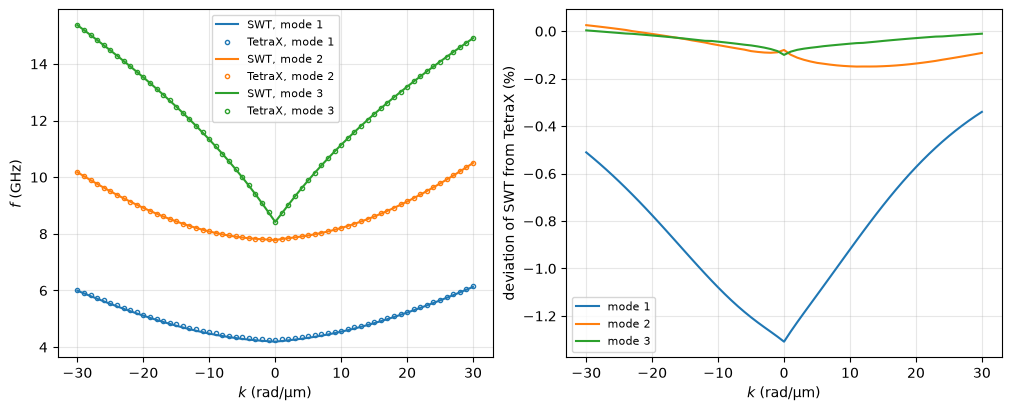

maximum deviation of the modes (%): [1.31 0.15 0.1 ]


In [5]:
def compare_plot(k, f_swt, k_tx, f_tx, names):
    """Plot the dispersions of both codes and the relative deviation."""
    f_tx_cmp = np.array([np.interp(k, k_tx, f) for f in f_tx])  # TetraX on k
    dev = 100*(f_swt/f_tx_cmp - 1)  # (%) deviation of SWT from TetraX
    fig, axs = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
    for i, name in enumerate(names):
        axs[0].plot(k*1e-6, f_swt[i], "-", color=f"C{i}", label=f"SWT, {name}")
        axs[0].plot(k_tx*1e-6, f_tx[i], "o", color=f"C{i}", ms=3, mfc="none",
                    label=f"TetraX, {name}")
        axs[1].plot(k*1e-6, dev[i], "-", color=f"C{i}", label=name)
    axs[0].set_xlabel("$k$ (rad/µm)")
    axs[0].set_ylabel("$f$ (GHz)")
    axs[0].legend(fontsize=8)
    axs[1].set_xlabel("$k$ (rad/µm)")
    axs[1].set_ylabel("deviation of SWT from TetraX (%)")
    axs[1].legend(fontsize=8)
    for ax in axs:
        ax.grid(alpha=0.3)
    plt.show()
    print("maximum deviation of the modes (%):",
          np.round(np.abs(dev).max(axis=1), 2))


compare_plot(k, f_swt, k_tx, f_tx, ["mode 1", "mode 2", "mode 3"])

The three modes agree within about one percent (at most about 60 MHz), including the nonreciprocity, the non-collinear and tilted static state and the different anisotropies of the layers.  The remaining difference, largest for the lowest mode at small wavevectors, is mostly due to the nonuniformity (twist) of the static magnetization across the layers in TetraX, where the interlayer coupling acts at the interfaces only, which the macrospin layers of `MultiLayerNumeric` cannot describe (without the relaxation in TetraX, i.e. with the uniform static state of SpinWaveToolkit, the deviation is below 0.4 %); it grows with the coupling strength and the layer thickness, see also [SAF dispersion vs TetraX](SAF_dispersion_vs_TetraX.ipynb).

## 2. Thick film from exchange-coupled sublayers

The uniform-magnetization assumption of each layer can be relaxed by splitting a thick layer into thin sublayers coupled by the bilinear interlayer exchange ``Jbl = 2*Aex/d_sub`` without spacers, which is the finite-difference form of the exchange energy across the thickness.  A 40 nm thick Py film in an in-plane field of 50 mT perpendicular to the wavevector (Damon-Eshbach geometry) is modelled by 20 sublayers of 2 nm and compared with TetraX (a monolayer with the cell size of 1 nm).  The lowest modes are the nonreciprocal surface (Damon-Eshbach) mode and the perpendicular standing spin waves (PSSW).

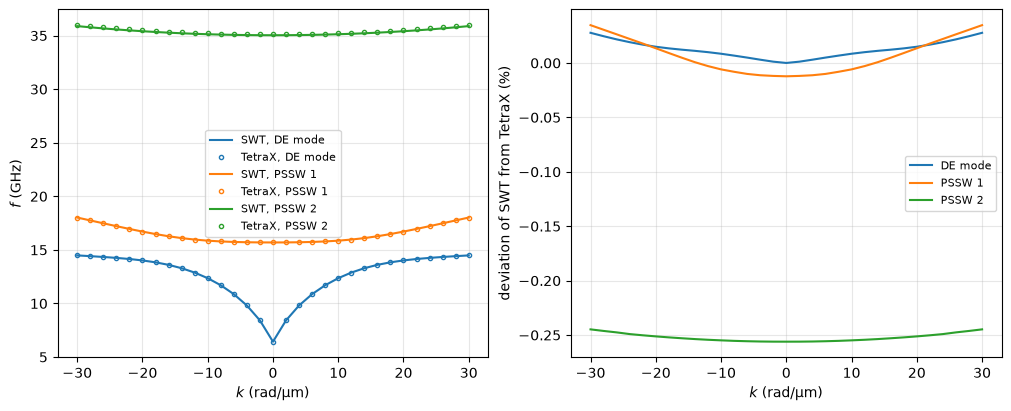

maximum deviation of the modes (%): [0.03 0.03 0.26]


In [6]:
D, n_sub = 40e-9, 20
k2 = np.linspace(-30e6, 30e6, 31)
film = SWT.MultiLayerNumeric(
    Bext=50e-3, material=Py, d=[D/n_sub]*n_sub, kxi=k2, theta=np.pi/2,
    phi=np.pi/2, s=0, Jbl=2*Py.Aex/(D/n_sub), phiInit=0,
)
angles2 = film.GetEquilibrium()  # (all sublayers along the field)
w2, v2 = film.GetDispersion(angles=angles2)
f2_swt = w2[:3]/(2e9*np.pi)  # (GHz) three lowest modes

# TetraX: a single 40 nm film (monolayer line trace with 1 nm cells)
workdir = os.path.abspath("tetrax_tmp")
os.makedirs(workdir, exist_ok=True)
cwd = os.getcwd()
os.chdir(workdir)
try:
    sample = tx.Sample(tx.geometries.layer.monolayer(D*1e9, 1.0), name="film")
    sample.material["Msat"] = Py.Ms
    sample.material["Aex"] = Py.Aex
    sample.material["gamma"] = Py.gamma
    sample.material["alpha"] = Py.alpha
    sample.Bext = film.Bext*to_tetrax(unit_vector(np.pi/2, 0.0, film.phi))
    sample.mag = to_tetrax(unit_vector(np.pi/2, 0.0, film.phi))
    for _ in range(5):  # (repeat until converged, see `tetrax_multilayer`)
        if tx.experiments.relax(sample, verbose=False, save=False,
                                set_initial_on_failure=False).was_success:
            break
    eigen = tx.experiments.eigenmodes(sample, k=k2[k2 >= 0], num_modes=3,
                                      save_mode_profiles=False,
                                      verbose=False, num_cpus=1)
    k2_tx = np.asarray(eigen.k)
    f2_tx = np.asarray(eigen.frequencies()).T/1e9  # (GHz)
finally:
    os.chdir(cwd)
    shutil.rmtree(workdir)

compare_plot(k2, f2_swt, k2_tx, f2_tx, ["DE mode", "PSSW 1", "PSSW 2"])

The surface mode and the first standing spin wave agree within a few hundredths of a percent and the second standing spin wave within a few tenths of a percent (the discretization error of the 2 nm sublayers).  The eigenvectors of `GetDispersion` give the mode profiles across the film thickness (the out-of-plane amplitudes of the sublayers), e.g. the surface localization of the Damon-Eshbach mode on the opposite surfaces for the opposite propagation directions:

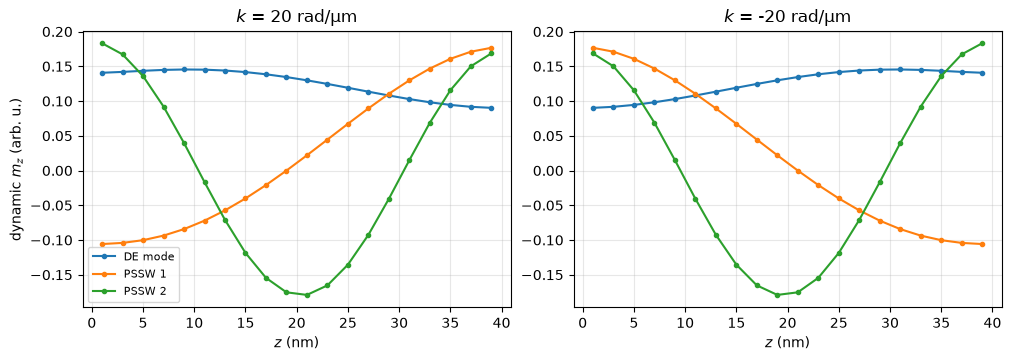

In [7]:
z = (np.arange(n_sub) + 0.5)*D/n_sub*1e9  # (nm) centers of the sublayers
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for ax, i in zip(axs, (np.argmin(abs(k2 - 20e6)), np.argmin(abs(k2 + 20e6)))):
    for n, name in enumerate(["DE mode", "PSSW 1", "PSSW 2"]):
        amp = v2[1::2, n, i]  # out-of-plane amplitudes of the sublayers
        amp = amp*np.exp(-1j*np.angle(amp[np.argmax(abs(amp))]))  # (real)
        ax.plot(z, np.real(amp), "o-", ms=3, label=name)
    ax.set_title(f"$k$ = {k2[i]*1e-6:.0f} rad/µm")
    ax.set_xlabel("$z$ (nm)")
    ax.grid(alpha=0.3)
axs[0].set_ylabel("dynamic $m_z$ (arb. u.)")
axs[0].legend(fontsize=8)
plt.show()